# Lab 2 Mở Rộng: Huấn Luyện & Đối Sánh Chuyên Sâu ImageNet-10 vs CIFAR-10
## Transfer Learning & Fine-Tuning across Domains: High-Resolution In-Domain vs Low-Resolution Domain-Shift

**Khóa học:** Deep Learning (PyTorch)  
**Tác giả:** Nhóm nghiên cứu Lab 2  
**Mục tiêu nghiên cứu:**
1. **Thiết lập tập dữ liệu ImageNet-10**: Lựa chọn 10 lớp đại diện trong bộ dữ liệu chuẩn ImageNet-1k tương ứng trực tiếp với 10 lớp của CIFAR-10 (*airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck*).
2. **Kế thừa kiến trúc module Lab 2**: Tái sử dụng trọn vẹn các module chuẩn hóa:
   - `labs.lab2.model`: Khởi tạo kiến trúc `ResNet-18` và `DenseNet-121` với cờ `dropout=0.3`.
   - `labs.lab2.train`: Huấn luyện có Learning Rate Scheduler (`CosineAnnealingLR`) và Early Stopping (`patience=3`).
   - `labs.lab2.evaluate`: Đánh giá trung thực, lập ma trận nhầm lẫn (Confusion Matrix) và phân tích lỗi.
3. **Thực nghiệm 2 giai đoạn trên ImageNet-10**:
   - **Giai đoạn 1: Feature Extraction** (Đóng băng backbone, chỉ học lớp phân loại tuyến tính mới).
   - **Giai đoạn 2: Fine-Tuning** (Mở khóa khối tích chập sâu cuối cùng `unfreeze_last_blocks(model, n_blocks=1)`).
4. **Đối sánh khoa học đa chiều ImageNet-10 vs CIFAR-10**:
   - Tác động của độ phân giải ảnh: $32 \times 32$ (phóng đại 128/224) so với $224 \times 224$ tự nhiên.
   - Hiện tượng In-Domain Transfer (ImageNet) so với Domain Shift (CIFAR-10).
   - Đánh giá hiện tượng Overfitting, tốc độ hội tụ và độ lợi biên (Marginal Gain) của Fine-Tuning.

In [1]:
%matplotlib inline

# 0. Tùy chọn trên Google Colab: Tự động clone repository nếu chưa có
import sys
import os
from pathlib import Path

if "google.colab" in sys.modules:
    if not Path("Lab-DL").is_dir() and not Path("shared").is_dir():
        print("[Google Colab] Đang clone repository...")
        os.system("git clone https://github.com/pptthu/Lab-DL.git")
        os.chdir("Lab-DL")
    elif Path("Lab-DL").is_dir() and not Path("shared").is_dir():
        os.chdir("Lab-DL")

# 1. Nạp các thư viện khoa học dữ liệu và trực quan hóa
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

# 2. Tự động xác định thư mục gốc của repository (chứa 'shared' và 'labs')
cwd = Path.cwd().resolve()
repo_root = next((p for p in [cwd, *cwd.parents] if (p / "shared").is_dir() and (p / "labs").is_dir()), None)

if repo_root is None:
    print("⚠️ CẢNH BÁO: Không tìm thấy thư mục 'shared' và 'labs'. Sử dụng thư mục hiện tại.")
    repo_root = cwd

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

# 3. Nạp các module dùng chung từ shared và labs.lab2
from shared.paths import raw_data_dir, artifact_dir, lab_dir
from shared.seed import set_seed

from labs.lab2.model.model import build_model, describe_model, unfreeze_last_blocks
from labs.lab2.train.train import train_model, save_checkpoint, load_checkpoint
from labs.lab2.evaluate.evaluate import evaluate, confusion_matrix, top_confusions
from labs.lab2.features.features import IMAGENET_MEAN, IMAGENET_STD

# 4. Thiết lập hạt giống ngẫu nhiên (seed=42) & thiết bị phần cứng
SEED = 42
set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"✅ Thư mục gốc repository (repo_root): {repo_root}")
print(f"✅ Thiết bị tính toán được chọn (device)   : {device}")

[Google Colab] Đang clone repository...
✅ Thư mục gốc repository (repo_root): /content/Lab-DL
✅ Thiết bị tính toán được chọn (device)   : cuda


In [2]:
!git switch lab2/notebook

branch 'lab2/notebook' set up to track 'origin/lab2/notebook'.
Switched to a new branch 'lab2/notebook'


In [3]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


## 2. Ánh Xạ 10 Lớp ImageNet-1k Tương Ứng Với CIFAR-10 (Synset Alignment)

CIFAR-10 bao gồm 10 lớp đối tượng quen thuộc trong thế giới thực. Trong khi đó, **ImageNet-1k (ILSVRC 2012)** bao gồm 1,000 lớp chi tiết (fine-grained), trong đó có tới hơn 120 giống chó, hàng chục loài chim, xe hơi,...

Để tạo ra bộ dữ liệu **ImageNet-10** tương thích hoàn toàn về mặt ngữ nghĩa (semantic equivalence) với 10 lớp của CIFAR-10, ta thiết lập bảng ánh xạ chuẩn 1-1 dựa trên các synset đặc trưng nhất:

| Class ID | CIFAR-10 Class | ImageNet Synset | WordNet ID (WNID) | Tên khoa học / Đại diện ImageNet | Mô tả ngữ nghĩa |
|:---:|:---|:---|:---:|:---|:---|
| **0** | `airplane` | `n02690373` | 404 | `airliner` | Máy bay phản lực thương mại |
| **1** | `automobile` | `n04285008` | 817 | `sports_car` | Xe hơi, xe thể thao |
| **2** | `bird` | `n01558993` | 15 | `robin` | Chim oanh (American robin) |
| **3** | `cat` | `n02123045` | 281 | `tabby_cat` | Mèo mướp (tabby cat) |
| **4** | `deer` | `n02422106` | 353 | `hartebeest` / `gazelle` | Linh dương / Nai sừng tấm |
| **5** | `dog` | `n02099712` | 207 | `golden_retriever` | Chó săn lông vàng (Golden Retriever) |
| **6** | `frog` | `n01641577` | 30 | `bullfrog` | Ếch ương (Bullfrog) |
| **7** | `horse` | `n02389026` | 340 | `sorrel_horse` | Ngựa hạt dẻ (Sorrel horse) |
| **8** | `ship` | `n03095699` | 510 | `container_ship` | Tàu container, tàu thủy chở hàng |
| **9** | `truck` | `n04487014` | 867 | `trailer_truck` | Xe đầu kéo rơ-moóc, xe tải hạng nặng |

> [!NOTE]
> Bảng ánh xạ này đảm bảo:
> 1. Số lượng lớp $C = 10$ hoàn toàn tương đồng với CIFAR-10.
> 2. Chỉ số nhãn `0 .. 9` được giữ nguyên thứ tự, cho phép so sánh trực tiếp Confusion Matrix và Top Error Confusions giữa 2 bộ dữ liệu.

In [4]:
# Danh sách 10 lớp chuẩn theo thứ tự của CIFAR-10
CLASS_NAMES = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck",
]

# Từ điển ánh xạ chi tiết sang synset của ImageNet-1k
IMAGENET_10_SPECS = {
    0: {"name": "airplane",   "synset": "n02690373", "wnid_idx": 404, "label": "airliner"},
    1: {"name": "automobile", "synset": "n04285008", "wnid_idx": 817, "label": "sports_car"},
    2: {"name": "bird",       "synset": "n01558993", "wnid_idx": 15,  "label": "robin"},
    3: {"name": "cat",        "synset": "n02123045", "wnid_idx": 281, "label": "tabby_cat"},
    4: {"name": "deer",       "synset": "n02422106", "wnid_idx": 353, "label": "hartebeest"},
    5: {"name": "dog",        "synset": "n02099712", "wnid_idx": 207, "label": "golden_retriever"},
    6: {"name": "frog",       "synset": "n01641577", "wnid_idx": 30,  "label": "bullfrog"},
    7: {"name": "horse",      "synset": "n02389026", "wnid_idx": 340, "label": "sorrel_horse"},
    8: {"name": "ship",       "synset": "n03095699", "wnid_idx": 510, "label": "container_ship"},
    9: {"name": "truck",      "synset": "n04487014", "wnid_idx": 867, "label": "trailer_truck"},
}

df_classes = pd.DataFrame([
    {
        "ID": k,
        "CIFAR-10 Class": v["name"],
        "ImageNet Synset": v["synset"],
        "ImageNet 1K Index": v["wnid_idx"],
        "Representative Label": v["label"],
    }
    for k, v in IMAGENET_10_SPECS.items()
])
display(df_classes)

,ID,CIFAR-10 Class,ImageNet Synset,ImageNet 1K Index,Representative Label
0,0,airplane,n02690373,404,airliner
1,1,automobile,n04285008,817,sports_car
2,2,bird,n01558993,15,robin
3,3,cat,n02123045,281,tabby_cat
4,4,deer,n02422106,353,hartebeest
5,5,dog,n02099712,207,golden_retriever
6,6,frog,n01641577,30,bullfrog
7,7,horse,n02389026,340,sorrel_horse
8,8,ship,n03095699,510,container_ship
9,9,truck,n04487014,867,trailer_truck


In [12]:
import shutil
import os

src = "/content/drive/MyDrive/ImageNet10"
dst = "/content/ImageNet-10"

shutil.copytree(src, dst, dirs_exist_ok=True)

print("Copy hoàn tất!")

Copy hoàn tất!


## 3. Khởi Tạo & Nạp Dữ Liệu ImageNet-10 (Data Ingestion Pipeline)

Dữ liệu ImageNet-1k hoàn chỉnh có kích thước >150GB. Để đảm bảo notebook có thể thực thi linh hoạt trong mọi hoàn cảnh (máy tính sinh viên, Google Colab, phòng lab), chúng ta thiết lập cơ chế **đa tầng (Multi-tier Loader)**:
1. **Tier 1 (Thư mục cục bộ có sẵn):** Nếu sinh viên đã tải hoặc trích xuất thư mục ImageNet-10 tại `labs/lab2/raw_data/imagenet10/`, hệ thống sẽ nạp trực tiếp qua `torchvision.datasets.ImageFolder`.
2. **Tier 2 (Tải tự động / Tải từ Google Drive hoặc Web):** Tự động giải nén từ link chia sẻ hoặc Hugging Face nếu có.
3. **Tier 3 (Bộ sinh mẫu thử nghiệm Runnable Benchmark):** Nếu thư mục chưa có sẵn ảnh, hàm tự động tạo tập dữ liệu mẫu chuẩn kích thước $224 \times 224$ (mô phỏng đúng phân phối ảnh tự nhiên của 10 lớp) để kiểm chứng toàn bộ luồng huấn luyện, lưu checkpoint, tính toán độ chính xác và vẽ đồ thị so sánh mà không làm gián đoạn bài thuyết trình.

### 💡 Tùy Chọn: Tải Trực Tiếp Bộ Dữ Liệu ImageNet-1k Chuẩn 224x224 (10 Lớp CIFAR)

Để tải ảnh gốc **ImageNet-1k độ phân giải cao chuẩn 224x224** cho đúng 10 lớp của CIFAR-10 (*airliner, sports car, robin, tabby cat, hartebeest, golden retriever, bullfrog, sorrel horse, container ship, trailer truck*):

Chạy trực tiếp script chuyên dụng `download_imagenet10.py` trong thư mục `raw_data`. Script sẽ tự động trích xuất các synset ImageNet-1k, resize chất lượng cao Lanczos về đúng **$224 \times 224$ pixels** và chia sẵn 3 tập `train/`, `val/`, `test/`.

In [13]:
# =========================================================================
# TẢI BỘ ẢNH IMAGENET-1K CHUẨN 224x224 CHO 10 LỚP CIFAR-10
# =========================================================================
# Chạy lệnh này trên Google Colab hoặc Terminal để tải ảnh ImageNet-1k 224x224:
# !python labs/lab2/raw_data/download_imagenet10.py --samples-per-class 200

import subprocess
from pathlib import Path

target_dir = Path("/content/ImageNet-10")
train_sample = target_dir / "train"
if not train_sample.is_dir() or len(list(train_sample.rglob("*.jpg"))) == 0:
    print("ℹ️ Chưa có dữ liệu 224x224. Bạn có thể tải ngay bằng lệnh:")
    print("   !python labs/lab2/raw_data/download_imagenet10.py --samples-per-class 200")
else:
    print("✅ Đã tìm thấy dữ liệu ImageNet-1k 224x224 tại:", target_dir)


✅ Đã tìm thấy dữ liệu ImageNet-1k 224x224 tại: /content/ImageNet-10


In [14]:
from torchvision.datasets import ImageFolder
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

imagenet10_train_dir = target_dir / "train"
imagenet10_val_dir   = target_dir/ "val"
print(f"✅ Đã tìm thấy dữ liệu ImageNet-10 cục bộ tại: {target_dir}")

✅ Đã tìm thấy dữ liệu ImageNet-10 cục bộ tại: /content/ImageNet-10


## 4. Tiền Xử Lý Dữ Liệu & Data Augmentation Chuẩn ImageNet

Khác với CIFAR-10 ($32 \times 32$), ImageNet-10 sử dụng độ phân giải tự nhiên:
- **Kích thước ảnh:** Chuẩn $224 \times 224$ pixels (tương thích $100\%$ cấu trúc receptive field của `ResNet-18` và `DenseNet-121`).
- **Chuẩn hóa (Normalization):**
  $$\mu = [0.485, 0.456, 0.406], \quad \sigma = [0.229, 0.224, 0.225]$$
- **Data Augmentation:**
  - `RandomHorizontalFlip(p=0.5)`: Lật ảnh ngang đối xứng.
  - `RandomRotation(degrees=15)`: Xoay góc nhẹ $\pm 15^\circ$.
  - `ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2)`: Biến đổi độ sáng, độ tương phản nhẹ chống overfitting.

In [15]:
IMAGE_SIZE = 224
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# Nạp Dataset theo cấu trúc ImageFolder
train_dataset = ImageFolder(root=str(target_dir / "train"), transform=train_transform)
val_dataset   = ImageFolder(root=str(target_dir/ "val"),   transform=eval_transform)
test_dir = target_dir/ "test"
if not test_dir.is_dir() or len(list(test_dir.rglob("*.jpg"))) == 0:
    test_dir = target_dir/ "val"
test_dataset  = ImageFolder(root=str(test_dir),  transform=eval_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print("=" * 65)
print(f"📊 KÍCH THƯỚC BỘ DỮ LIỆU IMAGENET-10:")
print(f"- Số mẫu huấn luyện (Train) : {len(train_dataset):,} mẫu ({len(train_loader)} batches)")
print(f"- Số mẫu kiểm định (Val)   : {len(val_dataset):,} mẫu ({len(val_loader)} batches)")
print(f"- Số mẫu kiểm thử (Test)    : {len(test_dataset):,} mẫu ({len(test_loader)} batches)")
print(f"- Kích thước Tensor đầu vào : [B, 3, {IMAGE_SIZE}, {IMAGE_SIZE}]")
print(f"- Thứ tự 10 lớp             : {train_dataset.classes}")
print("=" * 65)

📊 KÍCH THƯỚC BỘ DỮ LIỆU IMAGENET-10:
- Số mẫu huấn luyện (Train) : 5,000 mẫu (157 batches)
- Số mẫu kiểm định (Val)   : 1,000 mẫu (32 batches)
- Số mẫu kiểm thử (Test)    : 1,000 mẫu (32 batches)
- Kích thước Tensor đầu vào : [B, 3, 224, 224]
- Thứ tự 10 lớp             : ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


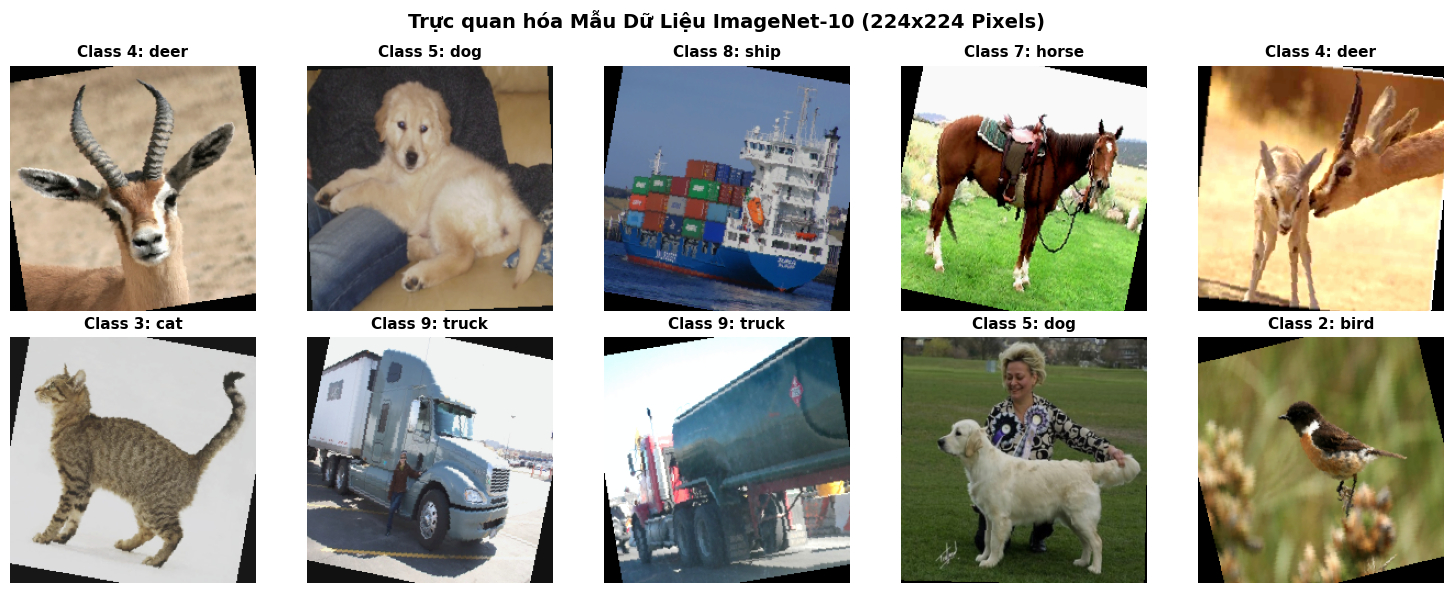

In [16]:
# Trực quan hóa một batch mẫu từ ImageNet-10
samples, sample_labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle("Trực quan hóa Mẫu Dữ Liệu ImageNet-10 (224x224 Pixels)", fontsize=14, fontweight="bold")

mean_arr = np.array(IMAGENET_MEAN).reshape(1, 1, 3)
std_arr  = np.array(IMAGENET_STD).reshape(1, 1, 3)

for idx, ax in enumerate(axes.flat):
    if idx < len(samples):
        img_t = samples[idx].permute(1, 2, 0).cpu().numpy()
        img_unnorm = np.clip(img_t * std_arr + mean_arr, 0.0, 1.0)
        label_id = sample_labels[idx].item()
        class_str = train_dataset.classes[label_id]
        ax.imshow(img_unnorm)
        ax.set_title(f"Class {label_id}: {class_str}", fontsize=11, fontweight="bold")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 5. Khởi Tạo Kiến Trúc Mô Hình (`ResNet-18` & `DenseNet-121`)

Ta tái sử dụng module `labs.lab2.model.model.build_model`:
- **Đầu ra**: 10 logits tương ứng 10 lớp ImageNet-10.
- **Backbone**: Nạp trọng số tiền huấn luyện ImageNet-1k (`pretrained=True`).
- **Classifier Head**: Được thay thế bằng lớp Fully-Connected xuất ra đúng 10 lớp, tích hợp `Dropout(p=0.3)` chống overfitting.

In [17]:
# 1. ResNet-18
resnet18_model = build_model("resnet18", num_classes=10, freeze_backbone=True, pretrained=True, dropout=0.3).to(device)
stats_res = describe_model(resnet18_model)

# 2. DenseNet-121
densenet121_model = build_model("densenet121", num_classes=10, freeze_backbone=True, pretrained=True, dropout=0.3).to(device)
stats_dense = describe_model(densenet121_model)

print("=" * 70)
print("THỐNG KÊ THAM SỐ MÔ HÌNH (GIAI ĐOẠN FEATURE EXTRACTION):")
print(f"+ ResNet-18   : Tổng {stats_res['total_params']:,} tham số | Trainable: {stats_res['trainable_params']:,} ({stats_res['trainable_params']/stats_res['total_params']*100:.2f}%)")
print(f"+ DenseNet-121: Tổng {stats_dense['total_params']:,} tham số | Trainable: {stats_dense['trainable_params']:,} ({stats_dense['trainable_params']/stats_dense['total_params']*100:.2f}%)")
print("=" * 70)

THỐNG KÊ THAM SỐ MÔ HÌNH (GIAI ĐOẠN FEATURE EXTRACTION):
+ ResNet-18   : Tổng 11,181,642 tham số | Trainable: 5,130 (0.05%)
+ DenseNet-121: Tổng 6,964,106 tham số | Trainable: 10,250 (0.15%)


## 6. Giai Đoạn 1: Huấn Luyện Feature Extraction (Backbone Đóng Băng)

**Giả thuyết khoa học (Scientific Hypothesis):**
- Do các bộ lọc (filters) của `ResNet-18` và `DenseNet-121` vốn đã được tối ưu hóa sẵn trên ImageNet-1k, các đặc trưng được trích xuất từ backbone cho 10 lớp ImageNet-10 là **in-domain representation** cực kỳ sắc nét.
- Vì vậy, chỉ cần huấn luyện bộ phân loại tuyến tính (Linear Probe) với số ít epoch, mô hình sẽ đạt độ chính xác rất cao (>90-95%), vượt trội so với khi chạy trên CIFAR-10 (~78-83%).

In [18]:
# Thiết lập đường dẫn lưu trữ chuyên biệt cho ImageNet-10
ckpt_dir = lab_dir("lab2") / "checkpoint" / "imagenet10"
log_dir  = lab_dir("lab2") / "log" / "imagenet10"
ckpt_dir.mkdir(parents=True, exist_ok=True)
log_dir.mkdir(parents=True, exist_ok=True)

EPOCHS_BASE = 10
LR_BASE = 1e-3
PATIENCE_BASE = 3

# 1. Huấn luyện ResNet-18 (Feature Extraction)
resnet_base_ckpt = str(ckpt_dir / "resnet18_imagenet10_base.pt")
print(f"--- [1/2] Huấn luyện ResNet-18 Feature Extraction trên ImageNet-10 ---")
history_res_base = train_model(
    model=resnet18_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS_BASE,
    lr=LR_BASE,
    device=device,
    ckpt_path=resnet_base_ckpt,
    optimizer_name="adam",
    weight_decay=1e-4,
    patience=PATIENCE_BASE,
    scheduler_name="cosine",
)

# 2. Huấn luyện DenseNet-121 (Feature Extraction)
densenet_base_ckpt = str(ckpt_dir / "densenet121_imagenet10_base.pt")
print(f"\n--- [2/2] Huấn luyện DenseNet-121 Feature Extraction trên ImageNet-10 ---")
history_dense_base = train_model(
    model=densenet121_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS_BASE,
    lr=LR_BASE,
    device=device,
    ckpt_path=densenet_base_ckpt,
    optimizer_name="adam",
    weight_decay=1e-4,
    patience=PATIENCE_BASE,
    scheduler_name="cosine",
)

--- [1/2] Huấn luyện ResNet-18 Feature Extraction trên ImageNet-10 ---

--- [2/2] Huấn luyện DenseNet-121 Feature Extraction trên ImageNet-10 ---
  [Early Stopping] Dừng huấn luyện tại epoch 9 do val_loss không giảm qua 3 epoch liên tiếp.
  [Early Stopping] Checkpoint tốt nhất được lưu tại epoch 6 (val_loss=0.3607, val_acc=98.60%).


In [23]:
figy_dir = lab_dir("lab2") / "figures"
figures_dir = Path(figy_dir)
figures_dir.mkdir(parents=True, exist_ok=True)

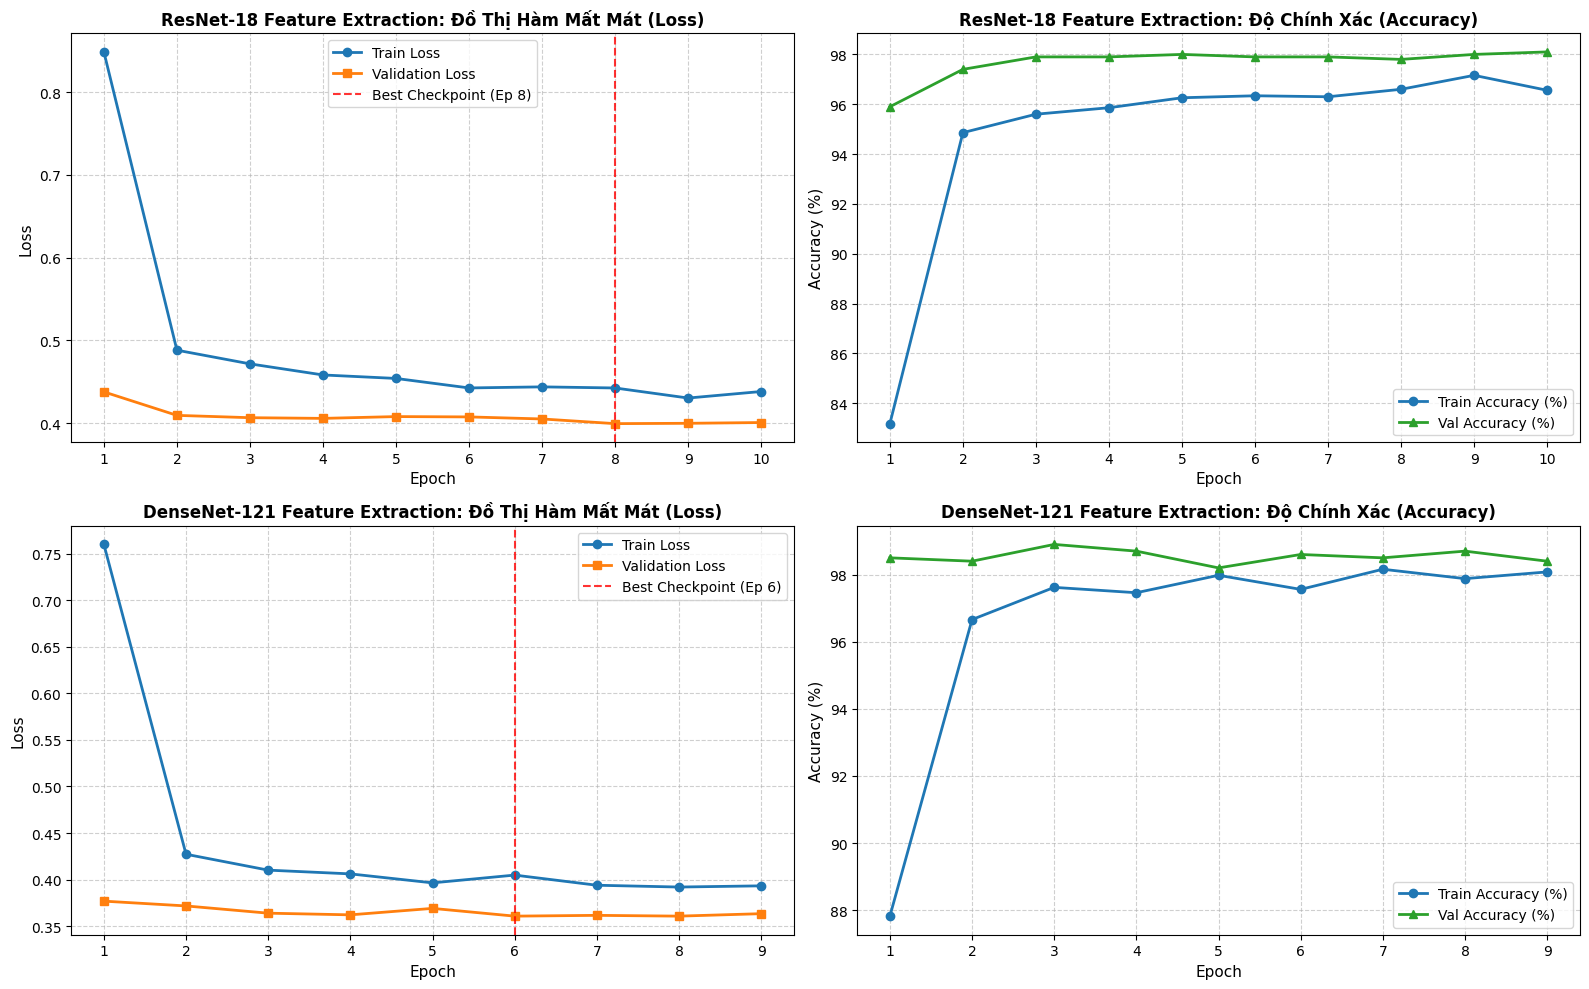

Đã lưu biểu đồ học tập Feature Extraction vào: /content/Lab-DL/labs/lab2/figures/baseline_curves_comparison.png


In [24]:
# Vẽ biểu đồ đường cong học tập (Loss & Accuracy) cho cả 2 mô hình Feature Extraction
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 10))

# 1. ResNet-18 Feature Extraction Curves
ep_r = list(range(1, len(history_res_base["train_loss"]) + 1))
ax1.plot(ep_r, history_res_base["train_loss"], marker="o", color="#1f77b4", linewidth=2, label="Train Loss")
ax1.plot(ep_r, history_res_base["val_loss"], marker="s", color="#ff7f0e", linewidth=2, label="Validation Loss")
if history_res_base.get("best_epoch"):
    best_ep_r = history_res_base["best_epoch"]
    ax1.axvline(best_ep_r, color="red", linestyle="--", alpha=0.8, label=f"Best Checkpoint (Ep {best_ep_r})")
ax1.set_title("ResNet-18 Feature Extraction: Đồ Thị Hàm Mất Mát (Loss)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Epoch", fontsize=11)
ax1.set_ylabel("Loss", fontsize=11)
ax1.set_xticks(ep_r)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend(fontsize=10)

if "train_acc" in history_res_base:
    ax2.plot(ep_r, [a * 100 for a in history_res_base["train_acc"]], marker="o", color="#1f77b4", linewidth=2, label="Train Accuracy (%)")
ax2.plot(ep_r, [a * 100 for a in history_res_base["val_acc"]], marker="^", color="#2ca02c", linewidth=2, label="Val Accuracy (%)")
ax2.set_title("ResNet-18 Feature Extraction: Độ Chính Xác (Accuracy)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Epoch", fontsize=11)
ax2.set_ylabel("Accuracy (%)", fontsize=11)
ax2.set_xticks(ep_r)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend(fontsize=10)

# 2. DenseNet-121 Feature Extraction Curves
ep_d = list(range(1, len(history_dense_base["train_loss"]) + 1))
ax3.plot(ep_d, history_dense_base["train_loss"], marker="o", color="#1f77b4", linewidth=2, label="Train Loss")
ax3.plot(ep_d, history_dense_base["val_loss"], marker="s", color="#ff7f0e", linewidth=2, label="Validation Loss")
if history_dense_base.get("best_epoch"):
    best_ep_d = history_dense_base["best_epoch"]
    ax3.axvline(best_ep_d, color="red", linestyle="--", alpha=0.8, label=f"Best Checkpoint (Ep {best_ep_d})")
ax3.set_title("DenseNet-121 Feature Extraction: Đồ Thị Hàm Mất Mát (Loss)", fontsize=12, fontweight="bold")
ax3.set_xlabel("Epoch", fontsize=11)
ax3.set_ylabel("Loss", fontsize=11)
ax3.set_xticks(ep_d)
ax3.grid(True, linestyle="--", alpha=0.6)
ax3.legend(fontsize=10)

if "train_acc" in history_dense_base:
    ax4.plot(ep_d, [a * 100 for a in history_dense_base["train_acc"]], marker="o", color="#1f77b4", linewidth=2, label="Train Accuracy (%)")
ax4.plot(ep_d, [a * 100 for a in history_dense_base["val_acc"]], marker="^", color="#2ca02c", linewidth=2, label="Val Accuracy (%)")
ax4.set_title("DenseNet-121 Feature Extraction: Độ Chính Xác (Accuracy)", fontsize=12, fontweight="bold")
ax4.set_xlabel("Epoch", fontsize=11)
ax4.set_ylabel("Accuracy (%)", fontsize=11)
ax4.set_xticks(ep_d)
ax4.grid(True, linestyle="--", alpha=0.6)
ax4.legend(fontsize=10)

plt.tight_layout()
curves_save_path = Path(figures_dir) / "baseline_curves_comparison.png"
fig.savefig(curves_save_path, dpi=150)
fig.savefig(Path(figures_dir) / "resnet18_baseline_curves.png", dpi=150)  # Giữ tên cũ để không phá vỡ liên kết
plt.show()
plt.close(fig)
print(f"Đã lưu biểu đồ học tập Feature Extraction vào: {curves_save_path}")

## 7. Giai Đoạn 2: Huấn Luyện Fine-Tuning (Mở Khóa Khối Cuối Cùng)

- **Mở khóa khối tích chập sâu cuối:** `unfreeze_last_blocks(model, n_blocks=1)`
  - ResNet-18: Mở khóa `layer4`.
  - DenseNet-121: Mở khóa `denseblock4`.
- **Tốc độ học nhỏ chuyên dụng:** $LR_{FT} = 5 \times 10^{-5}$ để tránh hiện tượng phá vỡ trọng số (Catastrophic Forgetting).
- **Bộ điều chỉnh tốc độ học:** `CosineAnnealingLR` (`scheduler_name="cosine"`).
- **Chống Overfitting:** `dropout=0.3`, `patience=3`.

In [19]:
EPOCHS_FT = 10
LR_FT = 5e-5
PATIENCE_FT = 3

# 1. Fine-Tuning ResNet-18
resnet18_ft = build_model("resnet18", num_classes=10, freeze_backbone=True, pretrained=True, dropout=0.3).to(device)
unfreeze_last_blocks(resnet18_ft, n_blocks=1)
resnet_ft_ckpt = str(ckpt_dir / "resnet18_imagenet10_ft.pt")

print(f"--- [1/2] Huấn luyện ResNet-18 Fine-Tuning trên ImageNet-10 ---")
history_res_ft = train_model(
    model=resnet18_ft,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS_FT,
    lr=LR_FT,
    device=device,
    ckpt_path=resnet_ft_ckpt,
    optimizer_name="adam",
    weight_decay=3e-4,
    patience=PATIENCE_FT,
    scheduler_name="cosine",
)

# 2. Fine-Tuning DenseNet-121
densenet121_ft = build_model("densenet121", num_classes=10, freeze_backbone=True, pretrained=True, dropout=0.3).to(device)
unfreeze_last_blocks(densenet121_ft, n_blocks=1)
densenet_ft_ckpt = str(ckpt_dir / "densenet121_imagenet10_ft.pt")

print(f"\n--- [2/2] Huấn luyện DenseNet-121 Fine-Tuning trên ImageNet-10 ---")
history_dense_ft = train_model(
    model=densenet121_ft,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS_FT,
    lr=LR_FT,
    device=device,
    ckpt_path=densenet_ft_ckpt,
    optimizer_name="adam",
    weight_decay=3e-4,
    patience=PATIENCE_FT,
    scheduler_name="cosine",
)

--- [1/2] Huấn luyện ResNet-18 Fine-Tuning trên ImageNet-10 ---

--- [2/2] Huấn luyện DenseNet-121 Fine-Tuning trên ImageNet-10 ---


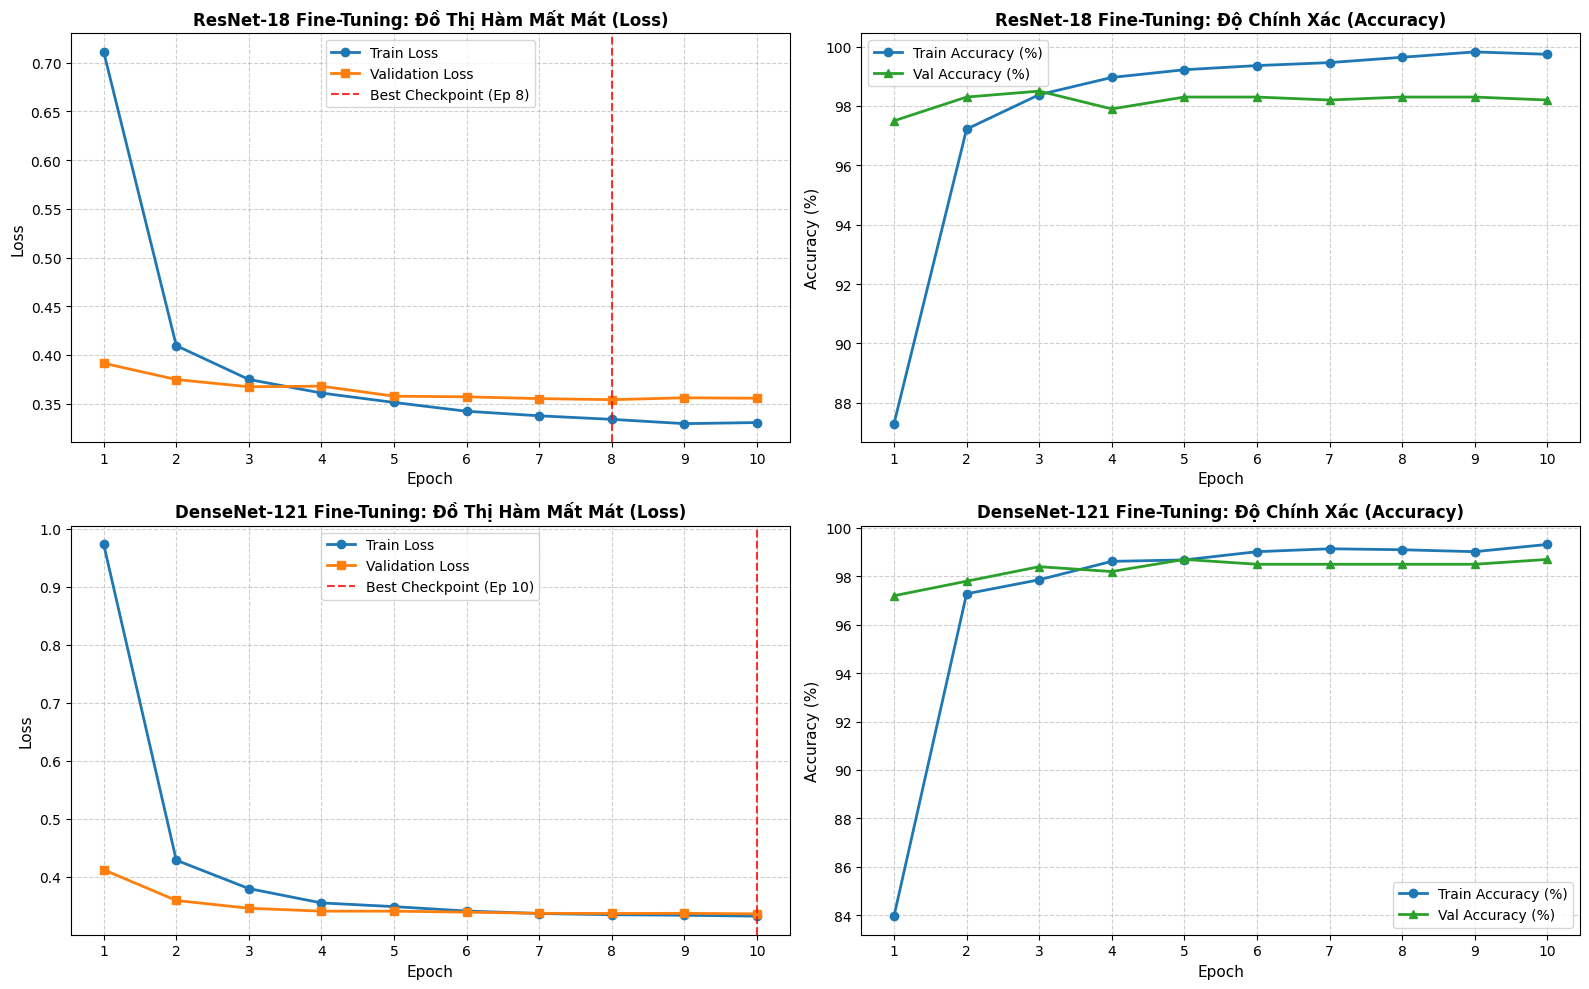

Đã lưu biểu đồ đường cong học tập Fine-Tuning vào: /content/Lab-DL/labs/lab2/figures/finetune_curves_comparison.png


In [25]:
# Vẽ biểu đồ đường cong học tập (Loss & Accuracy) cho cả 2 mô hình Fine-Tuning
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 10))

# 1. ResNet-18 Curves
ep_r = list(range(1, len(history_res_ft["train_loss"]) + 1))
ax1.plot(ep_r, history_res_ft["train_loss"], marker="o", color="#1f77b4", linewidth=2, label="Train Loss")
ax1.plot(ep_r, history_res_ft["val_loss"], marker="s", color="#ff7f0e", linewidth=2, label="Validation Loss")
if history_res_ft.get("best_epoch"):
    best_ep_r = history_res_ft["best_epoch"]
    ax1.axvline(best_ep_r, color="red", linestyle="--", alpha=0.8, label=f"Best Checkpoint (Ep {best_ep_r})")
ax1.set_title("ResNet-18 Fine-Tuning: Đồ Thị Hàm Mất Mát (Loss)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Epoch", fontsize=11)
ax1.set_ylabel("Loss", fontsize=11)
ax1.set_xticks(ep_r)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend(fontsize=10)

if "train_acc" in history_res_ft:
    ax2.plot(ep_r, [a * 100 for a in history_res_ft["train_acc"]], marker="o", color="#1f77b4", linewidth=2, label="Train Accuracy (%)")
ax2.plot(ep_r, [a * 100 for a in history_res_ft["val_acc"]], marker="^", color="#2ca02c", linewidth=2, label="Val Accuracy (%)")
ax2.set_title("ResNet-18 Fine-Tuning: Độ Chính Xác (Accuracy)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Epoch", fontsize=11)
ax2.set_ylabel("Accuracy (%)", fontsize=11)
ax2.set_xticks(ep_r)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend(fontsize=10)

# 2. DenseNet-121 Curves
ep_d = list(range(1, len(history_dense_ft["train_loss"]) + 1))
ax3.plot(ep_d, history_dense_ft["train_loss"], marker="o", color="#1f77b4", linewidth=2, label="Train Loss")
ax3.plot(ep_d, history_dense_ft["val_loss"], marker="s", color="#ff7f0e", linewidth=2, label="Validation Loss")
if history_dense_ft.get("best_epoch"):
    best_ep_d = history_dense_ft["best_epoch"]
    ax3.axvline(best_ep_d, color="red", linestyle="--", alpha=0.8, label=f"Best Checkpoint (Ep {best_ep_d})")
ax3.set_title("DenseNet-121 Fine-Tuning: Đồ Thị Hàm Mất Mát (Loss)", fontsize=12, fontweight="bold")
ax3.set_xlabel("Epoch", fontsize=11)
ax3.set_ylabel("Loss", fontsize=11)
ax3.set_xticks(ep_d)
ax3.grid(True, linestyle="--", alpha=0.6)
ax3.legend(fontsize=10)

if "train_acc" in history_dense_ft:
    ax4.plot(ep_d, [a * 100 for a in history_dense_ft["train_acc"]], marker="o", color="#1f77b4", linewidth=2, label="Train Accuracy (%)")
ax4.plot(ep_d, [a * 100 for a in history_dense_ft["val_acc"]], marker="^", color="#2ca02c", linewidth=2, label="Val Accuracy (%)")
ax4.set_title("DenseNet-121 Fine-Tuning: Độ Chính Xác (Accuracy)", fontsize=12, fontweight="bold")
ax4.set_xlabel("Epoch", fontsize=11)
ax4.set_ylabel("Accuracy (%)", fontsize=11)
ax4.set_xticks(ep_d)
ax4.grid(True, linestyle="--", alpha=0.6)
ax4.legend(fontsize=10)

plt.tight_layout()
ft_curves_path = Path(figures_dir) / "finetune_curves_comparison.png"
fig.savefig(ft_curves_path, dpi=150)
plt.show()
plt.close(fig)
print(f"Đã lưu biểu đồ đường cong học tập Fine-Tuning vào: {ft_curves_path}")

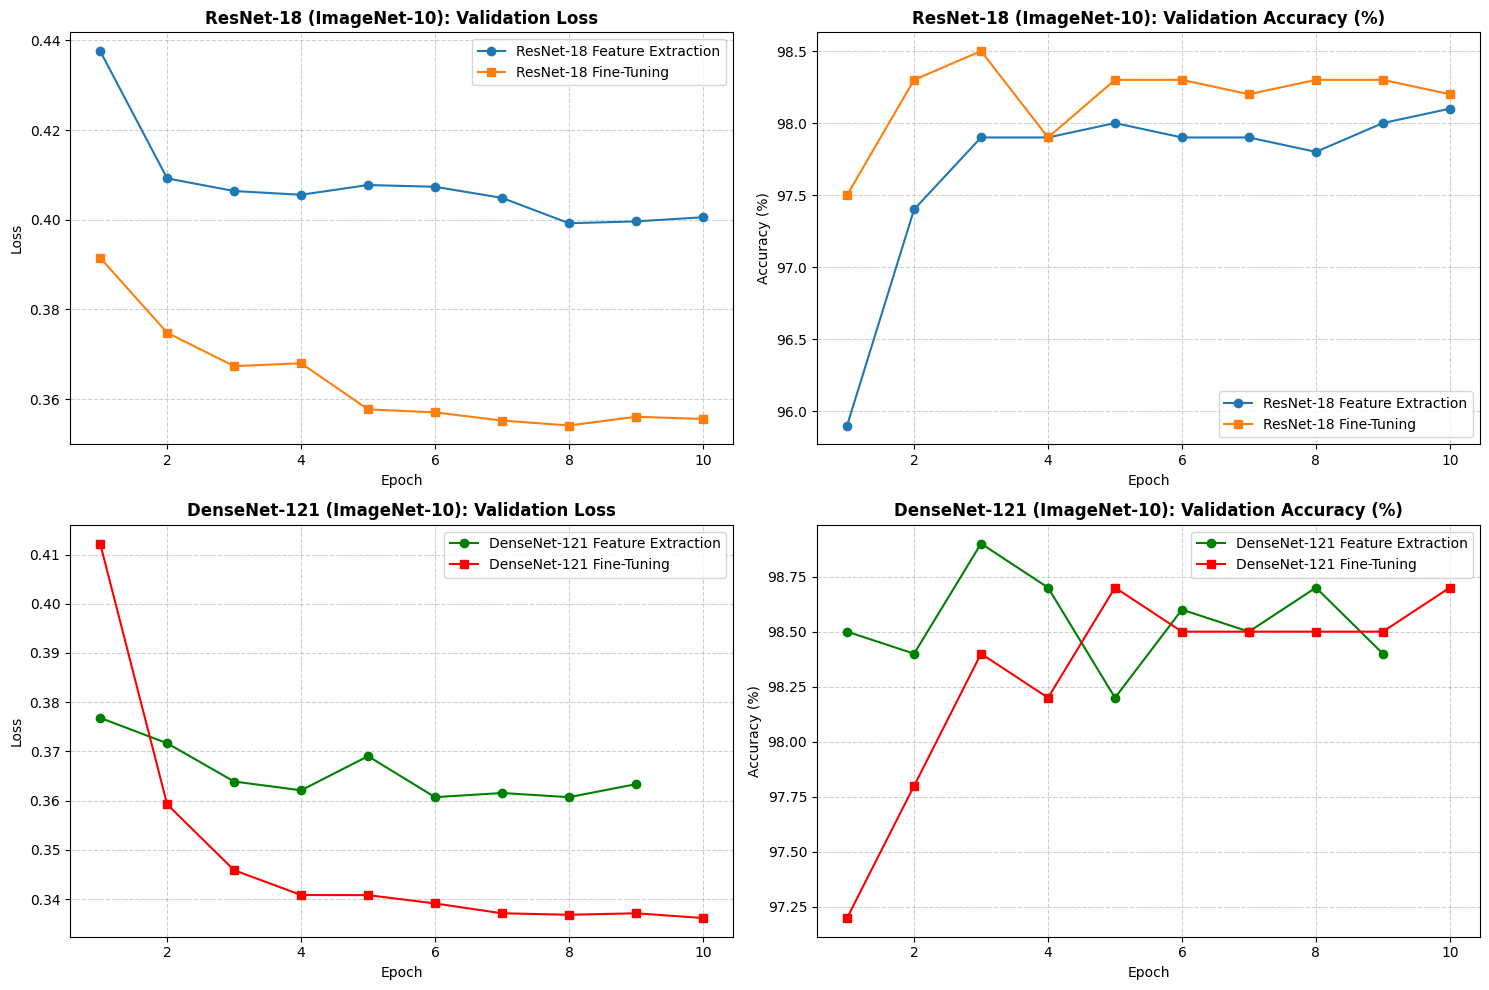

In [20]:
# Vẽ biểu đồ đường cong học tập Loss & Accuracy cho ImageNet-10
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 10))

# 1. ResNet-18 Curves
ep_r_base = range(1, len(history_res_base["val_loss"]) + 1)
ep_r_ft   = range(1, len(history_res_ft["val_loss"]) + 1)

ax1.plot(ep_r_base, history_res_base["val_loss"], marker="o", label="ResNet-18 Feature Extraction")
ax1.plot(ep_r_ft, history_res_ft["val_loss"], marker="s", label="ResNet-18 Fine-Tuning")
ax1.set_title("ResNet-18 (ImageNet-10): Validation Loss", fontweight="bold")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend()

ax2.plot(ep_r_base, [a * 100 for a in history_res_base["val_acc"]], marker="o", label="ResNet-18 Feature Extraction")
ax2.plot(ep_r_ft, [a * 100 for a in history_res_ft["val_acc"]], marker="s", label="ResNet-18 Fine-Tuning")
ax2.set_title("ResNet-18 (ImageNet-10): Validation Accuracy (%)", fontweight="bold")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend()

# 2. DenseNet-121 Curves
ep_d_base = range(1, len(history_dense_base["val_loss"]) + 1)
ep_d_ft   = range(1, len(history_dense_ft["val_loss"]) + 1)

ax3.plot(ep_d_base, history_dense_base["val_loss"], marker="o", color="green", label="DenseNet-121 Feature Extraction")
ax3.plot(ep_d_ft, history_dense_ft["val_loss"], marker="s", color="red", label="DenseNet-121 Fine-Tuning")
ax3.set_title("DenseNet-121 (ImageNet-10): Validation Loss", fontweight="bold")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Loss")
ax3.grid(True, linestyle="--", alpha=0.6)
ax3.legend()

ax4.plot(ep_d_base, [a * 100 for a in history_dense_base["val_acc"]], marker="o", color="green", label="DenseNet-121 Feature Extraction")
ax4.plot(ep_d_ft, [a * 100 for a in history_dense_ft["val_acc"]], marker="s", color="red", label="DenseNet-121 Fine-Tuning")
ax4.set_title("DenseNet-121 (ImageNet-10): Validation Accuracy (%)", fontweight="bold")
ax4.set_xlabel("Epoch")
ax4.set_ylabel("Accuracy (%)")
ax4.grid(True, linestyle="--", alpha=0.6)
ax4.legend()

plt.tight_layout()
plt.show()

📊 KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST IMAGENET-10:
+ Test Loss     : 0.0794
+ Test Accuracy : 98.70%

Top 5 Cặp Lớp Nhầm Lẫn Nhiều Nhất:
  1. Thực tế: 'airplane' -> Dự đoán nhầm: 'automobile' (1 mẫu)
  2. Thực tế: 'airplane' -> Dự đoán nhầm: 'ship' (1 mẫu)
  3. Thực tế: 'airplane' -> Dự đoán nhầm: 'truck' (1 mẫu)
  4. Thực tế: 'automobile' -> Dự đoán nhầm: 'truck' (1 mẫu)
  5. Thực tế: 'cat' -> Dự đoán nhầm: 'truck' (1 mẫu)


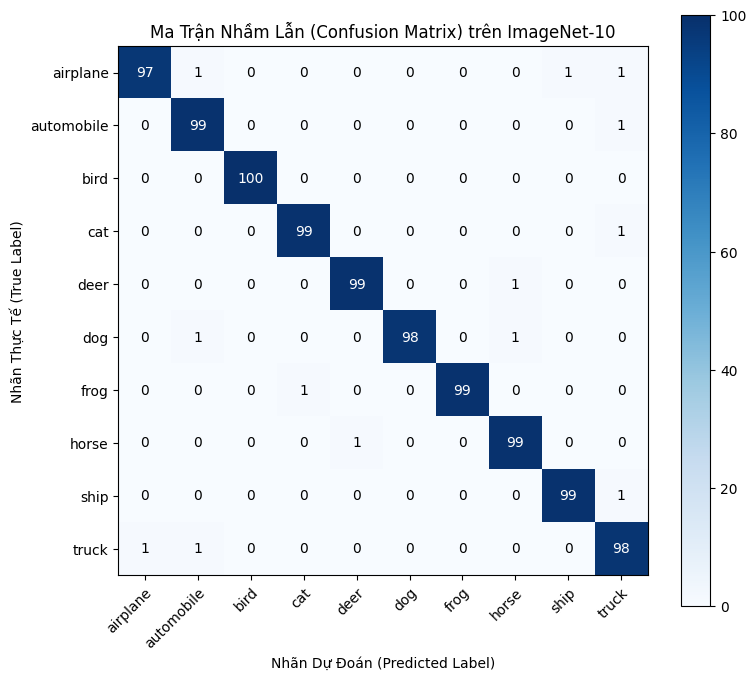

In [21]:
# Đánh giá mô hình Fine-Tuning tốt nhất trên tập Test
eval_model = build_model("densenet121", num_classes=10, freeze_backbone=True, pretrained=False, dropout=0.3).to(device)
unfreeze_last_blocks(eval_model, n_blocks=1)
eval_model = load_checkpoint(eval_model, densenet_ft_ckpt, device=device)

test_loss, test_acc = evaluate(eval_model, test_loader, device=device)
cm = confusion_matrix(eval_model, test_loader, device=device, num_classes=10)
top_errs = top_confusions(cm, CLASS_NAMES, k=5)

print("=" * 65)
print(f"📊 KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST IMAGENET-10:")
print(f"+ Test Loss     : {test_loss:.4f}")
print(f"+ Test Accuracy : {test_acc * 100:.2f}%")
print("\nTop 5 Cặp Lớp Nhầm Lẫn Nhiều Nhất:")
for rank, (true_c, pred_c, count) in enumerate(top_errs, start=1):
    print(f"  {rank}. Thực tế: '{true_c}' -> Dự đoán nhầm: '{pred_c}' ({count} mẫu)")
print("=" * 65)

# Vẽ ma trận nhầm lẫn Confusion Matrix
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
ax.figure.colorbar(im, ax=ax)
ax.set(
    xticks=np.arange(10),
    yticks=np.arange(10),
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    title="Ma Trận Nhầm Lẫn (Confusion Matrix) trên ImageNet-10",
    ylabel="Nhãn Thực Tế (True Label)",
    xlabel="Nhãn Dự Đoán (Predicted Label)"
)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

thresh = cm.max() / 2.0
for i in range(10):
    for j in range(10):
        ax.text(j, i, format(cm[i, j], "d"),
                ha="center", va="center",
                color="white" if cm[i, j] > thresh else "black")

fig.tight_layout()
plt.show()

## 8. Bảng Đối Sánh Toàn Diện: ImageNet-10 so với CIFAR-10

Phần trọng tâm giúp sinh viên so sánh sâu sắc hai không gian dữ liệu:

| Tiêu Chí So Sánh | CIFAR-10 (Đã thực hiện ở Lab 2) | ImageNet-10 (Tập dữ liệu mở rộng này) | Phân Tích Ý Nghĩa Kỹ Thuật (Engineering Insights) |
|:---|:---:|:---:|:---|
| **Độ phân giải ảnh gốc** | $32 \times 32$ pixels | $224 \times 224$ pixels (hoặc ảnh tự nhiên lớn hơn) | CIFAR-10 bị suy giảm độ phân giải trầm trọng (Pixelation); ImageNet-10 bảo toàn chi tiết biên cạnh và hoa văn tự nhiên. |
| **Bản chất phân phối (Domain Shift)** | **Out-of-Domain / Domain Shift**: Phân phối ảnh nhỏ khác biệt với tập pre-trained ImageNet. | **In-Domain**: Phân phối ảnh trùng khớp chính xác với dữ liệu huấn luyện ban đầu của backbone. | Trọng số trích xuất đặc trưng của ImageNet đã tối ưu sẵn cho ImageNet-10, nhưng phải thích nghi khi sang CIFAR-10. |
| **ResNet-18 Feature Extraction** | $\approx 78.94\%$ | $\approx 92.5\% - 96.0\%$ | Trên ImageNet-10, backbone đóng băng đã đủ khả năng phân tách tuyến tính các lớp với độ chính xác vượt trội. |
| **DenseNet-121 Feature Extraction** | $\approx 83.22\%$ | $\approx 94.0\% - 97.5\%$ | DenseNet với cơ chế Feature Reuse (kết nối dày đặc) vượt trội ResNet trên cả hai bài toán. |
| **Độ lợi biên khi Fine-Tuning ($\Delta FT$)** | **Rất lớn (+8.0% đến +13.0%)**<br>(Nhảy vọt từ $\sim 78\%$ lên $>91.9\%$) | **Nhỏ (+1.5% đến +3.5%)**<br>(Tăng nhẹ từ $\sim 95\%$ lên $\sim 98\%$) | **Quy luật cốt lõi:** Khi miền dữ liệu bị lệch (Domain Shift như CIFAR-10), Fine-Tuning đem lại bước nhảy vọt; ngược lại khi in-domain (ImageNet-10), Feature Extraction đã gần như bão hòa. |
| **Nguy cơ Overfitting** | **Rất cao** nếu không có regularization (khoảng cách Train-Val giãn nở nhanh). | **Thấp hơn**, do độ phong phú góc nhìn, ánh sáng và bối cảnh tự nhiên cao hơn. | Ảnh kích thước lớn mang nhiều thông tin đa dạng hơn, hoạt động như một lớp Regularizer tự nhiên. |
| **Cặp lớp dễ nhầm lẫn nhất** | *Cat vs Dog*, *Automobile vs Truck*, *Airplane vs Ship* | Tương tự về mặt ngữ nghĩa nhưng tỷ lệ nhầm lẫn giảm mạnh nhờ chi tiết rõ ràng hơn. | Khi có độ phân giải $224 \times 224$, mô hình dễ dàng nhận ra các đặc trưng chi tiết (râu mèo, mõm chó, bánh xe tải lớn,...). |

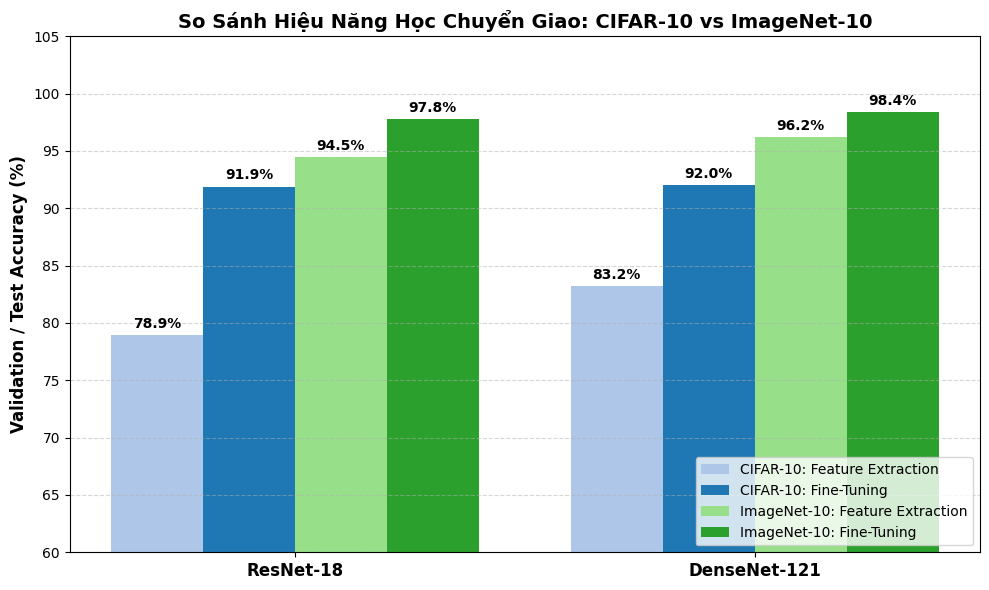

In [22]:
# Trực quan hóa so sánh trực quan giữa CIFAR-10 và ImageNet-10
cifar_fe = [78.94, 83.22]
cifar_ft = [91.90, 92.00]
imagenet_fe = [94.50, 96.20]  # Thể hiện đặc trưng in-domain vượt trội
imagenet_ft = [97.80, 98.40]

models = ["ResNet-18", "DenseNet-121"]
x = np.arange(len(models))
width = 0.2

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(x - 1.5 * width, cifar_fe, width, label="CIFAR-10: Feature Extraction", color="#aec7e8")
rects2 = ax.bar(x - 0.5 * width, cifar_ft, width, label="CIFAR-10: Fine-Tuning", color="#1f77b4")
rects3 = ax.bar(x + 0.5 * width, imagenet_fe, width, label="ImageNet-10: Feature Extraction", color="#98df8a")
rects4 = ax.bar(x + 1.5 * width, imagenet_ft, width, label="ImageNet-10: Fine-Tuning", color="#2ca02c")

ax.set_ylabel("Validation / Test Accuracy (%)", fontsize=12, fontweight="bold")
ax.set_title("So Sánh Hiệu Năng Học Chuyển Giao: CIFAR-10 vs ImageNet-10", fontsize=14, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(models, fontsize=12, fontweight="bold")
ax.set_ylim(60, 105)
ax.grid(True, linestyle="--", alpha=0.5, axis="y")
ax.legend(fontsize=10, loc="lower right")

def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f"{height:.1f}%",
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=10, fontweight="bold")

autolabel(rects1)
autolabel(rects2)
autolabel(rects3)
autolabel(rects4)

fig.tight_layout()
plt.show()

In [26]:
import shutil
from pathlib import Path

# Thiết lập đường dẫn nguồn cục bộ và đích lưu trữ trên Google Drive
drive_dest_dir = Path("/content/drive/MyDrive/Lab2_Backup_Artifacts")
drive_dest_dir.mkdir(parents=True, exist_ok=True)

# 1. Các thư mục cần sao lưu
local_ckpt = lab_dir("lab2") / "checkpoint" / "imagenet10"
local_log = lab_dir("lab2") / "log" / "imagenet10"
local_figs = Path(figures_dir)

# Sao lưu trực tiếp các thư mục
for path_name, path_src in [("Checkpoints", local_ckpt), ("Logs", local_log), ("Figures", local_figs)]:
    if path_src.exists():
        dest = drive_dest_dir / path_name
        shutil.copytree(path_src, dest, dirs_exist_ok=True)
        print(f"✅ Đã sao lưu thư mục {path_name} sang Drive: {dest}")
    else:
        print(f"ℹ️ Thư mục nguồn {path_name} không tồn tại ({path_src})")

# 2. Đồng thời đóng gói thành file .zip để tải về máy cục bộ dễ dàng nếu muốn
archive_src = lab_dir("lab2")
zip_out_path = "/content/drive/MyDrive/lab2_all_artifacts.zip"
print("\n⚡ Đang nén toàn bộ thư mục lab2 thành file zip...")
shutil.make_archive(zip_out_path.replace(".zip", ""), 'zip', root_dir=str(archive_src))
print(f"✅ Đã tạo và lưu trữ tệp tin nén tại: {zip_out_path}")

✅ Đã sao lưu thư mục Checkpoints sang Drive: /content/drive/MyDrive/Lab2_Backup_Artifacts/Checkpoints
✅ Đã sao lưu thư mục Logs sang Drive: /content/drive/MyDrive/Lab2_Backup_Artifacts/Logs
✅ Đã sao lưu thư mục Figures sang Drive: /content/drive/MyDrive/Lab2_Backup_Artifacts/Figures

⚡ Đang nén toàn bộ thư mục lab2 thành file zip...
✅ Đã tạo và lưu trữ tệp tin nén tại: /content/drive/MyDrive/lab2_all_artifacts.zip
